# Семинар 1. Библиотека `LightGBM`

`xgboost` и `LightGBM` работают на одном и том же алгоритме с небольшими различиями в реализации, поэтому результаты обучения бустинга в них будут почти идентичны. И хотя `xgboost` умеет работать во внешной памяти, библиотека отстаёт от `LightGBM` в реализации передовых идей. Поэтому в данном семинаре мы рассмотрим `LightGBM`.

> **Примечание.** К `xgboost` рекомендуется обращаться для чтения [туториалов](https://xgboost.readthedocs.io/en/latest/tutorials/index.html) по вопросам, которые не разобраны в документации `LightGBM`.


#### Подготовка

Для изучения библиотеки используем датасет [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult).

Попробуем предсказать, будет ли годовой доход человека выше 50 тысяч $ (бинарный таргет) в зависимости от его образования, семейного положения, работы и других показателей. Для удобства возьмём датасет из библиотеки `shap`, которую ты изучишь подробнее дальше на курсе.  


In [1]:
import numpy as np, pandas as pd
import shap

X, y = shap.datasets.adult()

y = pd.Series(y.astype(np.uint8))

X.info()
X.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             32561 non-null  float32
 1   Workclass       32561 non-null  int8   
 2   Education-Num   32561 non-null  float32
 3   Marital Status  32561 non-null  int8   
 4   Occupation      32561 non-null  int8   
 5   Relationship    32561 non-null  int64  
 6   Race            32561 non-null  int8   
 7   Sex             32561 non-null  int8   
 8   Capital Gain    32561 non-null  float32
 9   Capital Loss    32561 non-null  float32
 10  Hours per week  32561 non-null  float32
 11  Country         32561 non-null  int8   
dtypes: float32(5), int64(1), int8(6)
memory usage: 1.1 MB


,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39


In [2]:
# Ищем категориальные признаки в данных (простая проверка)
for col in X.columns:
    if X[col].nunique() < 15:
        print(X[col].value_counts(dropna=False, normalize=True).round(2))
        X[col] = X[col].astype('category') # xgboost и LightGBM понимают, что признаки типа 'category' — категориальные

Workclass
4    0.70
6    0.08
2    0.06
0    0.06
7    0.04
5    0.03
1    0.03
8    0.00
3    0.00
Name: proportion, dtype: float64
Marital Status
2    0.46
4    0.33
0    0.14
5    0.03
6    0.03
3    0.01
1    0.00
Name: proportion, dtype: float64
Relationship
4    0.41
0    0.26
3    0.16
1    0.11
5    0.05
2    0.03
Name: proportion, dtype: float64
Race
4    0.85
2    0.10
1    0.03
0    0.01
3    0.01
Name: proportion, dtype: float64
Sex
1    0.67
0    0.33
Name: proportion, dtype: float64


In [3]:
y.value_counts()

,count
0,24720
1,7841


In [4]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.33, shuffle=True, random_state=911)

## Основа `LightGBM`

Начнём изучение библиотеки и для начала рассмотрим минимальный код, который реализует обучение модели.

Дальше посмотрим, как добавить «надстройки» к этому коду, которые помогут в решении конкретных задач. Они не используются в каждой задаче, но часто нужны, чтобы улучшить качество решения.

> **Примечание.** Отдельно отметим, что у библиотеки `LightGBM` отличная [документация](https://lightgbm.readthedocs.io/en/latest/index.html), которую приятно изучать!




### Базовый код

Чтобы получить простой код обучения модели (своеобразный `fit-predict`), достаточно:
1. Обернуть `DataFrame` в специальную структуру `lgb.Dataset`.
2. Задать несколько основных параметров.

Получившаяся модель — это объект класса `lgb.Booster`. Подробнее изучить тему можно [здесь](https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.Booster.html#).

Кроме Training API, который будет использоваться в этом семинаре, в `LightGBM` есть scikit-learn API, который поддерживает меньшее количество настроек (в рамках семинара мы не будем его рассматривать).


In [16]:
cat_index = [i for i, col in enumerate(X_tr.columns) if isinstance(X_tr[col].dtype, pd.CategoricalDtype)]

In [18]:
import lightgbm as lgb

lgb_tr = lgb.Dataset(X_tr, y_tr, categorical_feature=cat_index)

params = {
    'objective': 'binary', # Задача: бинарная классификация → лосс='logloss'
    'eta': 0.1, # Learning rate
    'verbose': -1, # Позволяет не принтить лишние выводы

    'device_type': 'cpu', # 'cpu'/'gpu'/'cuda'. В LightGBM результаты обучения на cpu/gpu не отличаются
    'nthread': 8, # Количество ядер на процессоре для распараллеливания
}
model = lgb.train(params, train_set=lgb_tr, num_boost_round=50)

y_prob = model.predict(X_val) # «Вероятности» — scipy.special.expit (сумма весов)
y_raw = model.predict(X_val, raw_score=True) # «Сырые» скоры — сумма весов

print('y_prob:', y_prob[:5])
print('y_raw:', y_raw[:5])

y_prob: [0.03564526 0.13462605 0.9921696  0.2404382  0.01138418]
y_raw: [-3.29784312 -1.86066083  4.84188007 -1.15027861 -4.46408083]


> **Важно.** Модель может возвращать:
> - «сырые скоры» (сумму весов по всем деревьям);
> - «вероятности» (сырые скоры, пропущенные через функцию сигмоиды).
>
> Для анализа удобнее использовать именно «сырые» скоры, как видно на рисунке ниже.



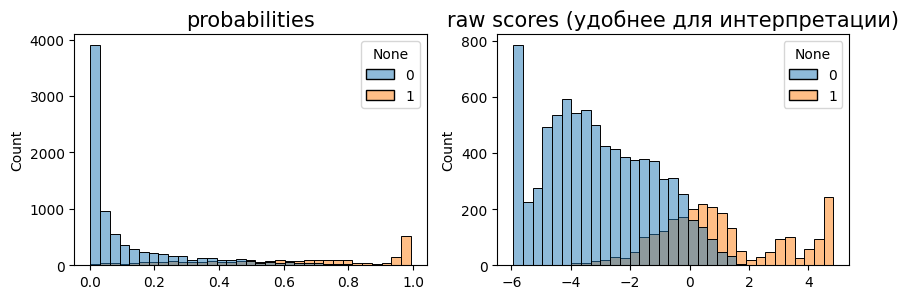

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplot_mosaic([['prob', 'raw']], figsize=(10, 3))

ax['prob'].set_title('probabilities', fontsize=15)
sns.histplot(x=y_prob, hue=y_val, bins=33, ax=ax['prob'])

ax['raw'].set_title('raw scores (удобнее для интерпретации)', fontsize=15)
sns.histplot(x=y_raw, hue=y_val, bins=33, ax=ax['raw']);

### Сallbacks

Первое, чем можно дополнить базовый код, — это механизм раннего останова.

Важно вовремя останавливаться, так как в бустингах принцип «чем больше деревьев, тем лучше» не работает, и из-за этого происходит переобучение. Для раннего останова (и не только) в `LightGBM` реализован механизм колбэков (callback).

Можно сказать, что это функции, которые:
* запускаются до/после построения каждого дерева;
* могут считать/выводить различные метрики;
* проверяют, не нужно ли остановиться.

Рассмотрим все доступные «из коробки» колбэки:
* `early_stopping` — настраиваем критерий останова.
* `log_evaluation` — выводим метрики в процессе обучения.
* `record_evaluation` — логируем метрики в словарик для дальнейшего изучения.

Подробнее изучить аргументы каждого из них можно [здесь](https://lightgbm.readthedocs.io/en/latest/Python-API.html#callbacks).



In [11]:
X_tr.dtypes

,0
Age,float32
Workclass,category
Education-Num,float32
Marital Status,category
Occupation,int8
Relationship,category
Race,category
Sex,category
Capital Gain,float32
Capital Loss,float32


In [21]:
lgb_val = lgb.Dataset(X_val, y_val)

params.update({
    'metric': 'auc' # Метрика, на которую смотрим, — ROC-AUC. '' — мерить objective loss, 'None' — метрика отсутствует
})
model = lgb.train(
    params, train_set=lgb_tr, num_boost_round=400,
    valid_sets=[lgb_val],
    valid_names=['необязательное название выборки'],
    callbacks=[lgb.log_evaluation(10), lgb.early_stopping(10)] # , lgb.early_stopping(10) # Сравним без ES и с ES
)

Training until validation scores don't improve for 10 rounds
[10]	необязательное название выборки's auc: 0.916709
[20]	необязательное название выборки's auc: 0.923406
[30]	необязательное название выборки's auc: 0.92683
[40]	необязательное название выборки's auc: 0.929182
[50]	необязательное название выборки's auc: 0.930556
[60]	необязательное название выборки's auc: 0.931326
[70]	необязательное название выборки's auc: 0.931859
[80]	необязательное название выборки's auc: 0.932329
[90]	необязательное название выборки's auc: 0.93254
[100]	необязательное название выборки's auc: 0.932664
[110]	необязательное название выборки's auc: 0.932687
Early stopping, best iteration is:
[105]	необязательное название выборки's auc: 0.932725


In [22]:
params.update({
    # Можно задать список метрик. Тогда в early_stopping можно настроить аргумент first_metric_only=True/False
    'metric': ['auc', 'binary_logloss']
})

model = lgb.train(
    params, train_set=lgb_tr, num_boost_round=1000,
    valid_sets=[lgb_val],
    callbacks=[lgb.early_stopping(10, first_metric_only=False), lgb.log_evaluation(10)]
)

Training until validation scores don't improve for 10 rounds
[10]	valid_0's auc: 0.916709	valid_0's binary_logloss: 0.3519
[20]	valid_0's auc: 0.923406	valid_0's binary_logloss: 0.304181
[30]	valid_0's auc: 0.92683	valid_0's binary_logloss: 0.286096
[40]	valid_0's auc: 0.929182	valid_0's binary_logloss: 0.277846
[50]	valid_0's auc: 0.930556	valid_0's binary_logloss: 0.273783
[60]	valid_0's auc: 0.931326	valid_0's binary_logloss: 0.271599
[70]	valid_0's auc: 0.931859	valid_0's binary_logloss: 0.270282
[80]	valid_0's auc: 0.932329	valid_0's binary_logloss: 0.269009
[90]	valid_0's auc: 0.93254	valid_0's binary_logloss: 0.268438
[100]	valid_0's auc: 0.932664	valid_0's binary_logloss: 0.268216
[110]	valid_0's auc: 0.932687	valid_0's binary_logloss: 0.267954
Early stopping, best iteration is:
[105]	valid_0's auc: 0.932725	valid_0's binary_logloss: 0.267986


С помощью колбэка `record_evaluation` можно:

1. Собрать сразу несколько метрик в процессе обучения.

2. Выбрать по графику, на каком дереве лучше остановиться.

Для эксперимента добавим L1-лосс. Чтобы его рассчитать, в качестве предсказываемых ответов используем «вероятности» классов, а в качестве правильных ответов возьмём метки `0, 1`.



In [23]:
params.update({
    'metric': ['auc', 'binary_logloss', 'l1']
})

# Можно собрать наши метрики при обучении в словарик через callback record_evaluation
evals_result = dict()

model = lgb.train(
    params, train_set=lgb_tr, num_boost_round=401,
    valid_sets=[lgb_val],
    callbacks=[lgb.record_evaluation(evals_result)]
)
print('Посмотрим на наш словарик после обучения модели:')
print('evals_result keys:\t\t\t', evals_result.keys())
print('evals_result["valid_0"] keys:\t\t', evals_result['valid_0'].keys())
print('evals_result["valid_0"]["auc"] len:\t', len(evals_result['valid_0']['auc']))

Посмотрим на наш словарик после обучения модели:
evals_result keys:			 dict_keys(['valid_0'])
evals_result["valid_0"] keys:		 odict_keys(['auc', 'binary_logloss', 'l1'])
evals_result["valid_0"]["auc"] len:	 401


Напишем функцию для отрисовки собранных метрик после обучения модели.

In [24]:
from matplotlib import colormaps

def plot_lgb_evals(evals_result, ax=None, skip_first=0):
    '''
    Рисует замеры одной или нескольких метрик во время обучения lgbm-модели

    evals_result — словарь из lgb.train вида evals_result['valid_0']
    skip_first: int — пропустить k первых деревьев для стабильности графика
    '''
    plot_df = pd.DataFrame(evals_result)
    metric_names = plot_df.columns
    plot_df = plot_df.melt(var_name='metric_name', value_name='value')
    plot_df['iter'] = plot_df.groupby('metric_name')['value'].cumcount()


    cmap = colormaps['tab10'].colors
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 4))

    ax.set_xlabel(f'iter (starts from {skip_first})')

    for i, metric_name in enumerate(metric_names):
        data = plot_df.query('metric_name == @metric_name').iloc[skip_first:]
        cur_ax = ax.twinx()
        p, = cur_ax.plot(data.iter, data.value, label=metric_name, color=cmap[i])
        x_max, x_min = np.argmax(data.value.values), np.argmin(data.value.values)

        cur_ax.annotate(f'{data.value.iloc[x_max]:.3f}', xy=(data.iter.iloc[x_max], data.value.iloc[x_max]), color=cmap[i], fontsize=13)
        cur_ax.annotate(f'{data.value.iloc[x_min]:.3f}', xy=(data.iter.iloc[x_min], data.value.iloc[x_min]), color=cmap[i], fontsize=13)

        cur_ax.spines.right.set_position(('axes', 1 + 0.2 * i))
        cur_ax.set(ylabel=metric_name)
        cur_ax.yaxis.label.set_color(p.get_color())
        cur_ax.tick_params(axis='y', colors=p.get_color())

        for place in ['top', 'left']:
            cur_ax.spines[place].set_visible(False)
            ax.spines[place].set_visible(False)

    ax.get_yaxis().set_visible(False)
    plt.show()

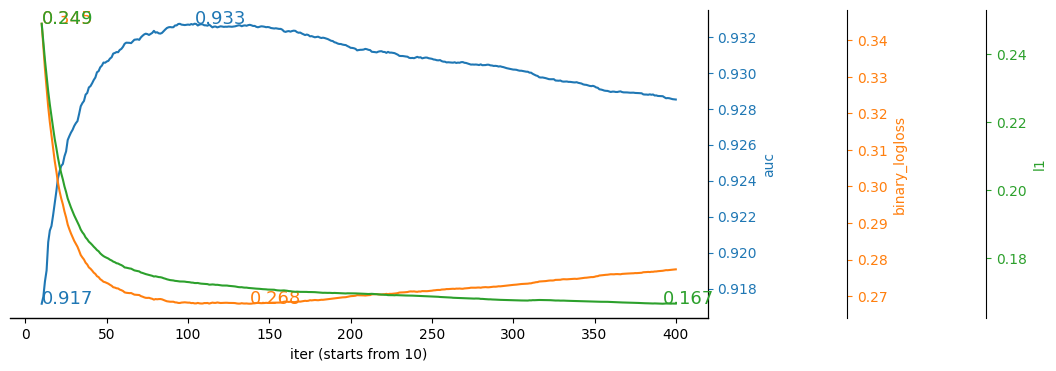

In [25]:
plot_lgb_evals(evals_result['valid_0'], skip_first=10)

На рисунке подписями отмечены максимальные и минимальные значения собранных метрик/лоссов. Как мы видим, оптимальные точки останова для каждой метрики находятся в разных местах: если для `ROC-AUC` и `LogLoss` они примерно одинаковы, то для L1 лосса точка останова находится на последнем дереве и, вероятно, ещё не достигнута.



#### Пользовательские метрики

Часто возникает потребность реализовать собственную метрику:
* чтобы отслеживать её в процессе обучения;

* искать по ней оптимальную точку останова.

Например, это может быть F1-мера, которой нет в `LightGBM`, или другая метрика, нечувствительная к ошибке величиной меньше ϵ.

Часто это связано с тем, что бизнес-заказчик задаёт метрики, которые не реализованы «из коробки». Так бизнес может мерить качество решения задачи по математическому ожиданию прибыли, а не по непонятной ему метрике `ROC-AUC`. В данном случае полезно будет отследить эту прибыль при обучении и, может быть, настроить по ней ранний останов.

Кастомная метрика в базовом варианте в `LightGBM` работает по следующему шаблону:
```python
def my_custom_metric(preds: np.array, eval_data: lgb.Dataset):
    '''
    preds: вектор предсказаний модели на текущей итерации для выборки eval_data
        (та, что пользователь задаёт через аргумент valid_sets)

    eval_data: lgb.Dataset, на котором мы считаем метрику
        Из него достаются метки и веса на объектах (если нужны)
    '''
    y_true = eval_data.get_label()
    object_weights = eval_data.get_weight()
    metric_score = calc_score(y_true, preds, weight)
    metric_name = 'my_custom_metric'
    greater_is_better = True
    return metric_name, metric_score, greater_is_better
```

> **Важно.**
> Если твоя модель учится на `LogLoss` (`objective='binary'`), в качестве `preds`
будут приходить «вероятности» — уже пропущенные через `scipy.special.expit` скоры.
> Если твоя модель учится на кастомном лоссе (об этом дальше), в `preds` будут подаваться «сырые» скоры.



#### Задание 1 [3 балла]

Реализуй F1-меру с порогом бинаризации `0.5` для решения задачи бинарной классификации со встроенным `LogLoss`. Веса на объектах использовать не нужно (не задавай их).

/tmp/ipykernel_5559/1709307304.py:9: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp/(tp + fp)


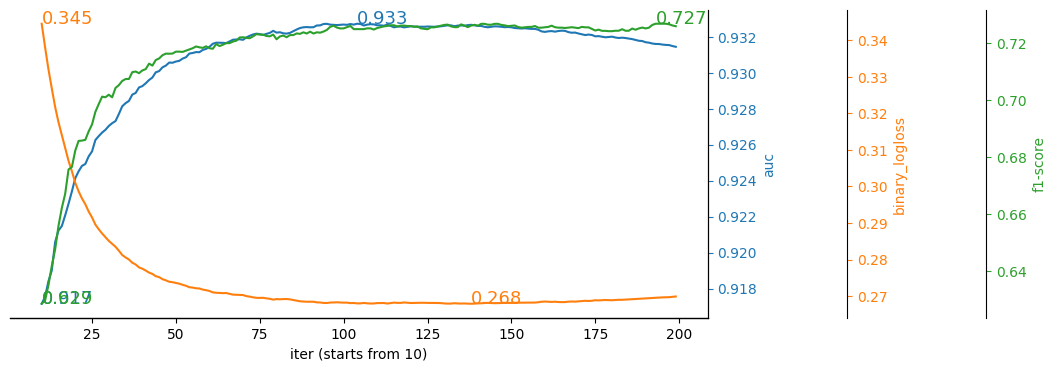

In [29]:
def custom_f1_score(preds: np.array, eval_data: lgb.Dataset):
    y_true = eval_data.get_label()
    y_pred = (preds > 0.5).astype(int)

    tp = ((y_true == 1) & (y_pred == 1)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    fn = ((y_true == 1) & (y_pred == 0)).sum()

    precision = tp/(tp + fp)
    recall = tp/(tp + fn)

    f1_score = 2 * precision * recall / (precision + recall)

    metric_name = 'f1-score'
    greater_is_better = True
    return metric_name, f1_score, greater_is_better

params.update({
    'metric': ['auc', 'binary_logloss']
})

evals_result = dict()
model = lgb.train(
    params, train_set=lgb_tr, num_boost_round=200,
    feval=custom_f1_score, # Кастомная метрика подаётся сюда. Можно также передать и список кастомных метрик
    valid_sets=[lgb_val],
    callbacks=[lgb.record_evaluation(evals_result)]
)

plot_lgb_evals(evals_result['valid_0'], skip_first=10)

### Кросс-валидация

В `LightGBM` есть встроенная функция кросс-валидации.

In [30]:
lgb_tr = lgb.Dataset(X_tr, y_tr)

params.update({
    'verbose': -1,
    'metric': ['auc', 'binary_logloss']
})

cv_res = lgb.cv(params, train_set=lgb_tr, num_boost_round=50, callbacks=[lgb.log_evaluation(10)])
print(cv_res.keys())

[10]	valid's auc: 0.908752 + 0.00568312	valid's binary_logloss: 0.36271 + 0.00495763
[20]	valid's auc: 0.916283 + 0.00598313	valid's binary_logloss: 0.316587 + 0.00708966
[30]	valid's auc: 0.919668 + 0.00571597	valid's binary_logloss: 0.299881 + 0.00780677
[40]	valid's auc: 0.922074 + 0.00530963	valid's binary_logloss: 0.292197 + 0.00787156
[50]	valid's auc: 0.923241 + 0.0052082	valid's binary_logloss: 0.288838 + 0.0080226
dict_keys(['valid auc-mean', 'valid auc-stdv', 'valid binary_logloss-mean', 'valid binary_logloss-stdv'])


### Веса на объектах при обучении

Часто необходимо задать веса на объектах обучающей выборки, чтобы перераспределить их вклад в обучение модели. Например:

1. В задачах бинарной классификации.

   В условиях, когда объектов класса 1 сильно меньше, чем объектов класса 0, можно задать им больший вес, чтобы модель относилась к ним более чутко.

2. В задаче, где у каждого объекта есть какой-то временной таймстемп (например, дата заказа  товара).

   Может быть логичнее учитывать последние заказы с большим весом, чем прошлогодние (старые данные могли устареть). Лучше задать небольшие веса «старым» объектам, чем не учитывать такие данные.


Веса на объектах в обучении модели — это множители при компонентах лосса, соответствующих объектам:
$$L_{total} = \sum_{i=1}^{N}{w_i \cdot L(y_i, \hat{y_i})} + regularization.$$

Тогда в формуле для оптимальных весов (= скоров в листьях), а следовательно, и в формуле для Gain $g_i \rightarrow w_i g_i, h_i \rightarrow w_i h_i$. То есть все «градиенты» и «гессианы» будут взвешиваться на веса (= веса на объектах). Так будет происходить во встроенных в LightGBM-лоссах, но при написании собственных ты можешь использовать веса на объектах по своему усмотрению (поговорим об этом далее).

В `LightGBM` можно явно передать вектор весов в `lgb.Dataset`, а для задач бинарной классификации — использовать два аргумента для быстрого задания весов:
- `is_unbalance`=True | $w_0 = 1, w_1 = n_0 / n_1$.
- `scale_pos_weight`=4.33 | $w_0 = 1, w_1 = scale\_pos\_weight$.

Рассмотрим оба способа задания весов, начиная с гиперпараметров.


/tmp/ipykernel_5559/1709307304.py:9: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp/(tp + fp)


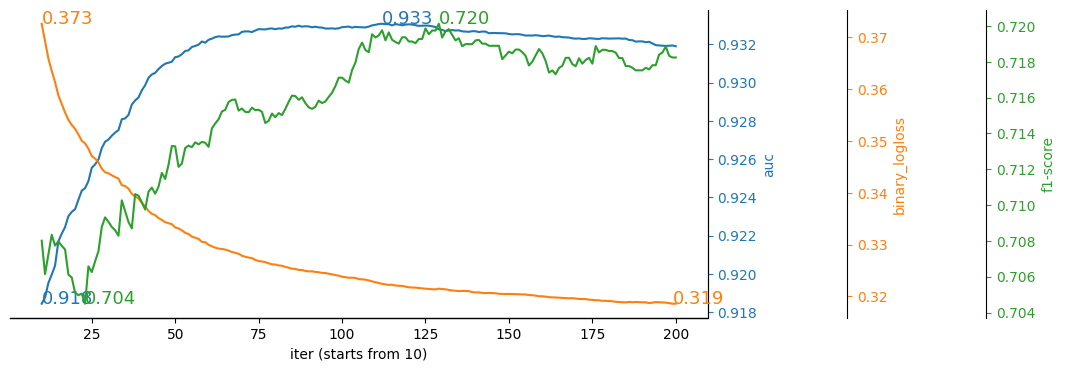

In [39]:
lgb_tr = lgb.Dataset(X_tr, y_tr)
lgb_val = lgb.Dataset(X_val, y_val)

params.update({
    # 'scale_pos_weight': 1, # w_0 = 1, w_1 = scale_pos_weight — веса класса 1 в бинарной классификации
    'is_unbalance': True # w_0 = 1, w_1 = n_1 / n_0 — автоматический «баланс» класса 1 в бинарной классификации. Не работает вместе с scale_pos_weight
})

evals_result = dict()
model = lgb.train(
    params, train_set=lgb_tr, num_boost_round=201,
    feval=custom_f1_score,
    valid_sets=[lgb_val],
    callbacks=[lgb.record_evaluation(evals_result)]
)
plot_lgb_evals(evals_result['valid_0'], skip_first=10)

#### Задача 2 [1 балл]

Как мы видим, траектории кривых и оптимальные точки поменялись по сравнению со схемой без весов.

Попробуй теперь самостоятельно настроить параметры `scale_pos_weight`: задай значения $0{,}1$, $10$, $100$ и посмотри на гистограммы скоров моделей с `hue=y_val`. Как меняются предсказания модели?


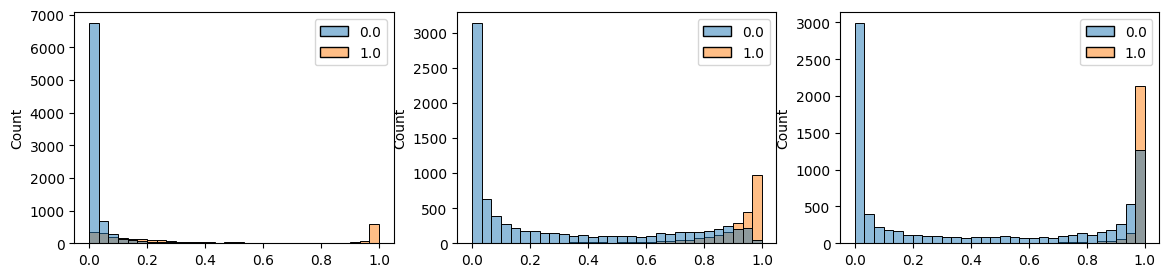

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
scale_pos_weights = [0.1, 10, 100]
for axis, scale_pos_weight in zip(axes, scale_pos_weights):
    params.update({
        'scale_pos_weight': scale_pos_weight,
        'is_unbalance': False
    })

    model = lgb.train(params, train_set=lgb_tr, num_boost_round=201)
    pred_val = model.predict(X_val)
    sns.histplot(x=pred_val, hue=lgb_val.get_label(), bins=30, ax=axis)

Передавая напрямую вектор в `lgb.Dataset`, нужно задать веса. Одна из неплохих практик — задавать веса, опираясь на значения какой-либо колонки в датасете (например, со временем). Мы рассмотрим числовую колонку Capital Gain. Что бы ни означала данная колонка, сделаем так, чтобы у объектов с бОльшим значением Capital Gain был бОльший вес.


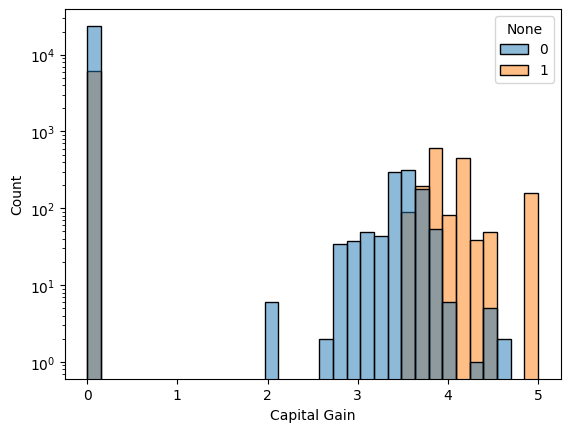

In [42]:
sns.histplot(x=np.log10(1 + X['Capital Gain']), hue=y, bins=33)
plt.yscale('log')

> **Важно.** При отсутствии специально заданных весов (когда все веса равны единице) они суммируются в N.

Помни про это правило, чтобы не нарушить процесс обучения неправильными порядками весов. Также следи за тем, чтобы веса не были нулевыми, поскольку это почти равносильно исключению таких объектов из обучающей выборки.


w.sum(): 21815.002 N: 21815
w: [0.76 0.76 0.76 0.76 0.76 3.68 0.76 0.76 0.76 3.68]


/tmp/ipykernel_5559/1709307304.py:9: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp/(tp + fp)


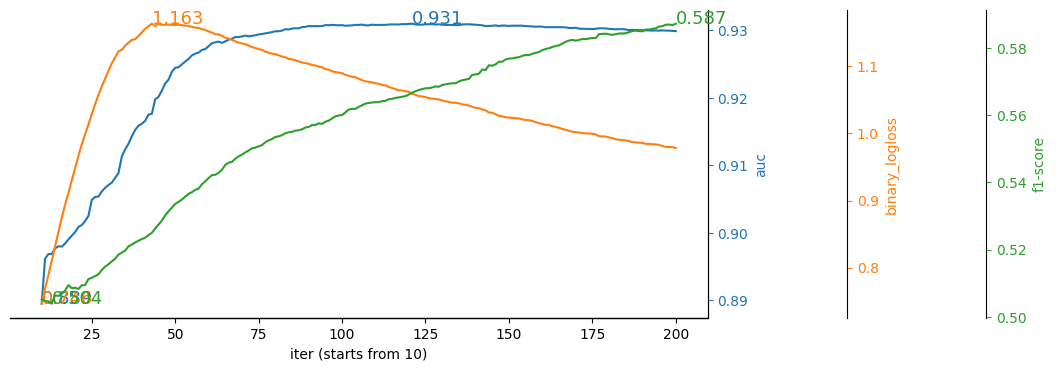

In [43]:
w = np.log10(X_tr['Capital Gain'] + 1) + 1
w = X_tr.shape[0] * w / w.sum()
print('w.sum():', w.sum(), 'N:', X_tr.shape[0])
print('w:', w.round(2).values[:10])

lgb_tr = lgb.Dataset(X_tr, y_tr, weight=w)
lgb_val = lgb.Dataset(X_val, y_val)

evals_result = dict()
model = lgb.train(
    params, train_set=lgb_tr, num_boost_round=201,
    feval=custom_f1_score, # Можно также передать и список кастомных метрик
    valid_sets=[lgb_val],
    callbacks=[lgb.record_evaluation(evals_result)]
)
plot_lgb_evals(evals_result['valid_0'], skip_first=10)

### Интерпретация

Интерпретируемость — одно из важнейших качеств моделей в ML. Зачастую намного важнее понимать, как модель «думает» и какие признаки ценит, чем получать хорошее качество без каких-либо инсайтов о данных. Эта информация:
* Поможет тебе объяснить заказчику, по каким показателям модель принимает решения или, например, какие из них важнее.
* Может натолкнуть тебя на мысли о том, что нужно сделать, чтобы улучшить качество решения.

В `LightGBM` есть метод, который выводит информацию о всех построенных деревьях вместе со сплитами, весами и другими данными в виде датафрейма, — `model.trees_to_dataframe()`.

Стоит отметить, что в колонке `value` записаны значения весов с учётом домножения на `learning_rate`. В нелистовых вершинах эти значения следует понимать как «если бы эта вершина была листом, значение в листе равнялось бы `value`».

Подробнее том, как извлекать полезную информацию из таблицы ниже, мы поговорим на семинаре по интерпретации моделей градиентного бустинга.




In [44]:
model.trees_to_dataframe()

,tree_index,node_depth,node_index,left_child,right_child,parent_index,split_feature,split_gain,threshold,decision_type,missing_direction,missing_type,value,weight,count
0,0,1,0-S0,0-S1,0-S2,None,Age,5443.580078,21.5,<=,left,None,-0.368026,171595.000000,21815
1,0,2,0-S1,0-L0,0-L2,0-S0,Marital_Status,1502.939941,2,==,right,NaN,-0.696013,504.536000,2096
2,0,3,0-L0,None,None,0-S1,None,NaN,None,None,None,None,-0.421527,136.088777,70
3,0,3,0-L2,None,None,0-S1,None,NaN,None,None,None,None,-0.799619,368.446848,2026
4,0,2,0-S2,0-S19,0-S3,0-S0,Relationship,990.741028,4||5,==,right,None,-0.367059,171090.000000,19719
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12256,200,7,200-S19,200-L19,200-L20,200-S18,Education-Num,27.701500,12.5,<=,left,None,-0.044153,19.820600,103
12257,200,8,200-L19,None,None,200-S19,None,NaN,None,None,None,None,-0.209095,6.726617,77
12258,200,8,200-L20,None,None,200-S19,None,NaN,None,None,None,None,0.040581,13.093942,26
12259,200,4,200-L9,None,None,200-S8,None,NaN,None,None,None,None,-0.130152,7.230200,141


Немного затронем метод `model.feature_importance()`, который агрегирует самую простую информацию о признаках из датафрейма с деревьями:
* `importance_type='split'` показывает, сколько раз каждый признак использовался в сплитах по всем деревьям.
* `importance_type='gain'` показывает, какой суммарный Gain имеют сплиты с каждым из признаков по всем деревьям.


feature_importances: [1421  179  819  163  678  185   43  162  962  389  823  206] 



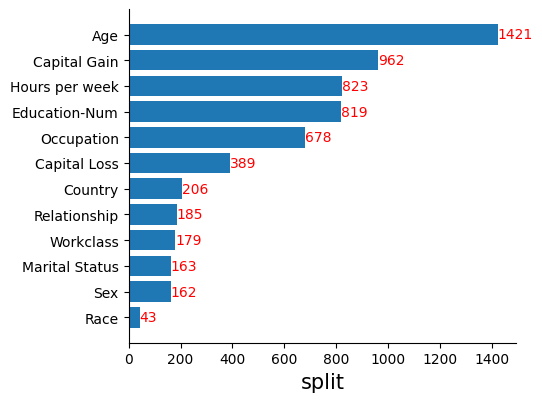

In [45]:
def plot_lgbm_importance(model, features, importance_type='split', top_k=20, round_to=0):
    '''
    importance_type: 'split' or 'gain'
    round_to: int — округление чисел на графике до round_to после запятой
    '''
    imps = model.feature_importance(importance_type=importance_type)

    idx = np.argsort(imps)
    sorted_imps = imps[idx][::-1][:top_k][::-1]
    sorted_features = features[idx][::-1][:top_k][::-1]
    if round_to == 0:
        sorted_imps = sorted_imps.astype(int)
    else:
        sorted_imps = np.round(sorted_imps, round_to)

    bar_container = plt.barh(width=sorted_imps, y=sorted_features)
    plt.bar_label(bar_container, sorted_imps, color='red')
    plt.gcf().set_size_inches(5, top_k/6 + 1)
    plt.xlabel(importance_type, fontsize=15)
    sns.despine()

print('feature_importances:', model.feature_importance(), '\n')
plot_lgbm_importance(model, X_tr.columns, importance_type='split')

>**Примечание.** В данном семинаре мы опускаем всё, что связано с `shap`, потому что далее на курсе мы разберём библиотеку подробно.

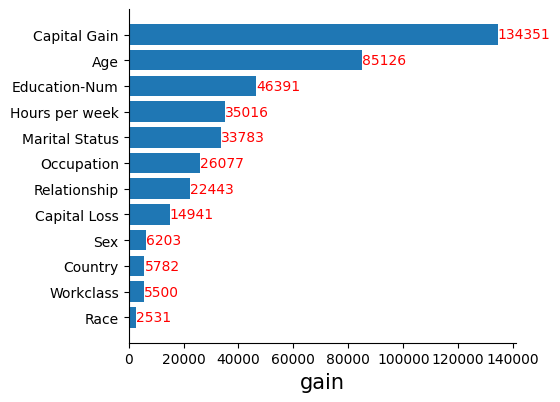

In [46]:
plot_lgbm_importance(model, X_tr.columns, importance_type='gain')

### Основные гиперпараметры

В этом блоке мы разберём основные гиперпараметры `LightGBM` — их смысл и советы по оптимальным значениям или их подбору. Стоит отметить, что в плане изменения итоговой метрики градиентный бустинг не очень чувствителен к изменению гиперпараметров. Однако он хорошо работает на гиперпараметрах «из коробки», поэтому перебирать гиперпараметры стоит в последнюю очередь. В любом случае всегда нужно знать свой арсенал и уметь настроить решение вручную или с помощью необходимых инструментов.

Подробнее изучить тему можно [здесь](https://lightgbm.readthedocs.io/en/latest/Parameters.html).


#### Темп обучения `eta`

Начнём с `eta`/`learning_rate` — самого важного гиперпараметра градиентного бустинга. Как правило, его подбор даёт наиболее заметный вклад в качество итоговой модели, а зависимость целевой метрики от него имеет понятный унимодальный вид вогнутой функции.

Вспомним, что с помощью `eta` домножаются оптимальные веса в листьях.
* С практической точки зрения этот параметр отвечает за «шаг обучения» или «уровень доверия дереву».
* С теоретической — `eta` работает как множитель потому, что при разложении лосса в ряд Тейлора мы подразумеваем малые веса. Из-за этого в зависимости от лосса изначальную формулу через «градиенты» и «гессианы» мы домножаем на малую константу (`eta`), чтобы наше приближение оставалось «наиболее справедливым» — то есть таким, при котором приблизительное равенство теряет как можно меньше информации.

Запустим подбор данного гиперпараметра с помощью библиотеки `optuna` и изучим получившиеся данные `ROC-AUC` в зависимости от `eta`.

In [47]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 11.0 MB/s eta 0:00:00


In [48]:
import optuna
from sklearn.metrics import roc_auc_score
from functools import partial

def objective(trial, X_tr, y_tr, X_val, y_val):
    lgb_tr = lgb.Dataset(X_tr, y_tr)
    lgb_val = lgb.Dataset(X_val, y_val)

    params = {
        'objective': 'binary',
        'nthread': 4,
        'verbose': 0,
        'metric': 'auc',
        'eta': trial.suggest_float('eta', 1e-3, 0.5, log=True)
    }

    model = lgb.train(
        params, lgb_tr, num_boost_round=1000,
        callbacks=[lgb.early_stopping(20, verbose=False)], valid_sets=[lgb_val]
    )
    y_raw = model.predict(X_val, raw_score=True)
    score = roc_auc_score(y_val, y_raw)
    return score

study = optuna.create_study(direction='maximize')
func = partial(objective, X_tr=X_tr, y_tr=y_tr, X_val=X_val, y_val=y_val)
study.optimize(func, n_trials=100, n_jobs=4)

[I 2026-03-23 08:32:12,922] A new study created in memory with name: no-name-7476d421-0888-445c-b3ca-66e6c0352fe4
[I 2026-03-23 08:32:21,500] Trial 3 finished with value: 0.9326911511853488 and parameters: {'eta': 0.06437709760152664}. Best is trial 3 with value: 0.9326911511853488.
[I 2026-03-23 08:32:22,758] Trial 1 finished with value: 0.9324411299607498 and parameters: {'eta': 0.0730386990084176}. Best is trial 3 with value: 0.9326911511853488.
[I 2026-03-23 08:32:26,272] Trial 2 finished with value: 0.932994647374197 and parameters: {'eta': 0.04196984956426491}. Best is trial 2 with value: 0.932994647374197.
[I 2026-03-23 08:32:39,473] Trial 6 finished with value: 0.932876072453471 and parameters: {'eta': 0.0425101554251245}. Best is trial 2 with value: 0.932994647374197.
[I 2026-03-23 08:32:56,920] Trial 5 finished with value: 0.9328010732768083 and parameters: {'eta': 0.01856019374750637}. Best is trial 2 with value: 0.932994647374197.
[I 2026-03-23 08:33:13,047] Trial 0 finishe

In [49]:
from optuna.visualization import plot_slice

plot_slice(study)

Как мы видим, в задаче нет чёткого максимума, но есть ровный участок хороших значений.

#### Категориальные гиперпараметры

Напомним, что если количество уникальных категорий в признаке меньше либо равно `max_cat_to_onehot`, то one-hot split вида $f_{cat} == A$ — потенциальный сплит.

Если же количество уникальных категорий в признаке больше `max_cat_to_onehot`, то потенциальный сплит partition split вида $f_{cat} \in \{'A', 'C', 'Y'\}$. В этом случае для такого сплита для категориального признака строится «гистограмма»:
1. Для каждого бина (значения категории) считаются сумма $g_i$ и сумма $h_i$.
2. Бины сортируются по значениям показателя $\frac{sum(g_i) + cat\_smooth}{sum(h_i) + cat\_l2}$.

После такой сортировки мы проходимся по данной гистограмме как по числовой, и подмножество значений, которое мы предлагаем для сплита — все бины, левее текущего «порога разбиения» (см. лонгрид).

`LightGBM` предлагает следующие параметры настройки:
* `max_cat_to_onehot` — самый важный категориальный параметр, который может сильно влиять на качество  (подбираем обычно в диапазоне `[2, 8]`).
- `cat_l2`, `cat_smooth` — как правило, не влияют на качество и не подбираются.
- `min_data_per_group` — бины с меньшим количеством объектов будут объединяться (для надёжности можно увеличить с «дефолтных» 100 ).
- `max_cat_threshold` — максимальное количество категориальных бинов (излишки будут объединяться в один бин). Можно пробовать увеличить или уменьшить значение, если задача сильно зависит от категориальных признаков (в таком случае лучше переключиться на `CatBoost`).


#### Предварительный биннинг / квантизация признаков

Перед построением любых деревьев происходит биннинг (квантизация) числовых признаков. Разберём гиперпараметры, позволяющие настроить этот процесс:
- `max_bins` = 255 — максимальное количество бинов для всех признаков (лучше оставить в дефолтном состоянии, чтобы хранение гистограмм было в `uint8`). На качество почти не влияет.
- `max_bin_by_feature` — можно настроить `max_bin` для каждого признака по отдельности (например, добавить бинов очень важному признаку).
- `min_data_in_bin` = 200 — можно увеличить для «надёжности» бинов.
- `zero_as_missing` = False — если поставить `True`, то нули тоже будут считаться за пропущенные значения (может быть полезно в определённых задачах).

#### Семплинг объектов и признаков

Учить все деревья можно:
* на полном наборе объектов и признаков,
* подмножествах.

Для начала рассмотрим семплирование признаков, которое может быть полезно для своего рода регуляризации модели и попытки «диверсифицировать» набор используемых ею признаков (снизить влияние какого-нибудь ценного признака, который она использует постоянно).

Используемые методы:

* `colsample_bytree` — задаём долю признаков, которая будет выделена из общего пула под каждое новое дерево (каждый раз — новое случайное подмножество).
* `colsample_bynode` — аналогично, но на каждую вершину (доли от прошлого и текущего гиперпараметров перемножаются).
* `feature_fraction_seed` — сид для семплинга признаков.

Есть две «стратегии» семплирования объектов:
- `data_sample_strategy`=`goss`: семплирует объекты с наибольшими ошибками и какую-то часть оставшихся объектов.
- `data_sample_strategy`=`bagging`: семплирует объекты случайно.

Если выбран `goss`, нужно также настроить параметры:
- `top_rate`, отвечающий за доли объектов с наибольшими ошибками;
- `other_rate`, отвечающий за долю из остальных объектов.

При выборе `bagging` нужно настроить параметры `bagging_freq` и `bagging_fraction`. Если `bagging_freq` = 1, то новое семплирование будет происходить для каждого дерева, если `bagging_freq` = 5 — для каждого пятого и так далее. Параметр `bagging_fraction` отвечает за долю объектов, которую мы будем семплировать. Так, `bagging_fraction` = 0,8 будет выбирать 80% случайных объектов для семплирования.

Для задачи бинарной классификации также используются гиперпараметры `pos_bagging_fraction` и `neg_bagging_fraction`, которые можно задать вместо «общего» параметра `bagging_freq` (его также нужно настроить) для настройки долей семплирования отдельно для классов 0 и 1. Обычно класс 0 в выборке сильно доминирует, поэтому семплирование может быть полезно, если большой дисбаланс классов доставляет проблемы.

Из всех этих вариантов семплирование класса 0 рекомендуется как способ избавиться от дисбаланса классов, если он есть. Если есть проблемы со скоростью, `goss` и `bagging` значительно ускорят процесс, семплируя примерно половину от всех объектов. Ниже — рисунок с замерами скорости работы разных схем семплирования.


In [50]:
from time import time as tm
from tqdm import tqdm
from sklearn.datasets import make_classification
import gc

def make_subsample_test_fair(n_trees):
    N = int(2e6)
    n_features = 200
    X_dummy, y_dummy = make_classification(N, n_features, n_informative=n_features, n_redundant=0, n_repeated=0, random_state=911)

    sizes = [50_000, 200_000, 500_000, 1_000_000, 2_000_000]

    time_plain = []
    time_goss_03 = []
    time_goss_06 = []
    time_subsample_03 = []
    time_subsample_06 = []

    for size in tqdm(sizes):
        params = {
            'nthread': 1,
            'verbose': -1,
            'device_type': 'cpu',
            'seed': 911,
        }
        data = lgb.Dataset(X_dummy[:size], label=y_dummy[:size])
        data.construct()

        # GOSS=0.3
        gc.collect()
        params.update({'data_sample_strategy': 'goss', 'top_rate': 0.2, 'other_rate': 0.1})
        stm = tm()
        model = lgb.train(params, data, num_boost_round=n_trees)
        time_goss_03.append(tm() - stm)

        # GOSS=0.6
        gc.collect()
        params.update({'data_sample_strategy': 'goss', 'top_rate': 0.4, 'other_rate': 0.2})
        stm = tm()
        model = lgb.train(params, data, num_boost_round=n_trees)
        time_goss_06.append(tm() - stm)

        # Plain
        gc.collect()
        params.update({'data_sample_strategy': 'bagging', 'bagging_freq': 0, 'bagging_fraction': 1.})
        stm = tm()
        model = lgb.train(params, data, num_boost_round=n_trees)
        time_plain.append(tm() - stm)

        # Subsample=0.3
        gc.collect()
        params.update({'data_sample_strategy': 'bagging', 'bagging_freq': 1, 'bagging_fraction': 0.3})
        stm = tm()
        model = lgb.train(params, data, num_boost_round=n_trees)
        time_subsample_03.append(tm() - stm)

        # Subsample=0.6
        gc.collect()
        params.update({'data_sample_strategy': 'bagging', 'bagging_freq': 1, 'bagging_fraction': 0.6})
        stm = tm()
        model = lgb.train(params, data, num_boost_round=n_trees)
        time_subsample_06.append(tm() - stm)

    return sizes, time_plain, time_goss_03, time_goss_06, time_subsample_03, time_subsample_06

sizes, time_plain, time_goss_03, time_goss_06, time_subsample_03, time_subsample_06 = make_subsample_test_fair(n_trees=100)

100%|██████████| 5/5 [35:33<00:00, 426.77s/it]


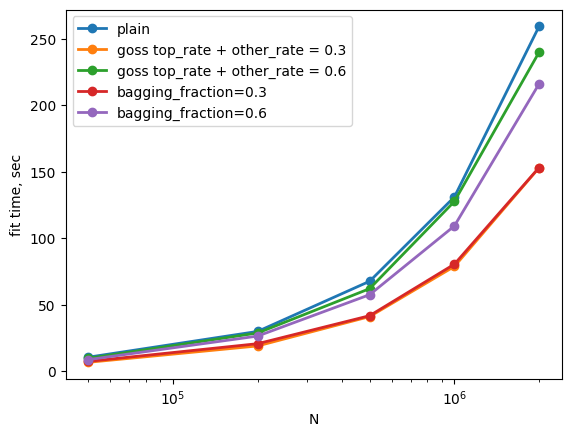

In [51]:
plt.plot(sizes, time_plain, lw=2, marker='o', label='plain')
plt.plot(sizes, time_goss_03, lw=2, marker='o', label='goss top_rate + other_rate = 0.3')
plt.plot(sizes, time_goss_06, lw=2, marker='o', label='goss top_rate + other_rate = 0.6')
plt.plot(sizes, time_subsample_03, lw=2, marker='o', label='bagging_fraction=0.3')
plt.plot(sizes, time_subsample_06, lw=2, marker='o', label='bagging_fraction=0.6')
plt.xscale('log')
plt.xlabel('N')
plt.ylabel('fit time, sec')
plt.legend();

Как мы видим, чем больше объектов в обучающей выборке, тем существеннее ускорение от семплирования. Как правило, это аналогично работает с количеством признаков.


#### Критерии останова

Эти гиперпараметры можно описать как «не трогать без нужды».

- `min_split_gain`=0 — $\gamma$-регуляризатор для количества листьев в деревьях. Влияет на минимальный Gain, необходимый для сплита (оставляем 0).
- `max_leaves` — максимальное количество листьев в дереве. Подбираем только по необходимости.
- `max_depth` — максимальная глубина деревьев. Не меняем — Lossguide-деревья не ограничивают глубиной, это искажает суть подхода.
- `min_data_in_leaf` — можно увеличить, чтобы увеличить «надёжность» листьев (чем больше объектов попало в лист, тем «надёжнее» его значение).
- `min_sum_hessian_in_leaf` — минимальная сумма гессианов в лист. Обычно не меняем. Вариативно используется, чтобы сделать веса меньше.


#### L1-, L2-регуляризаторы

При необходимости можно настроить регуляризацию на веса в листьях.

* `reg_alpha` = 0 — L1-регуляризация, которая понижает модуль весов и порождает нулевые.
* `reg_lambda` = 0 — L2-регуляризация, которая значительно понижает модуль весов.

Вспомним, что c учётом регуляризации формула для весов выглядит так:
```python
if |sum_grad| < reg_alpha:
    w = 0
else:
    w = - sign(sum_grad) * (|sum_grad| - reg_alpha) / (sum_hess + reg_lambda)
```


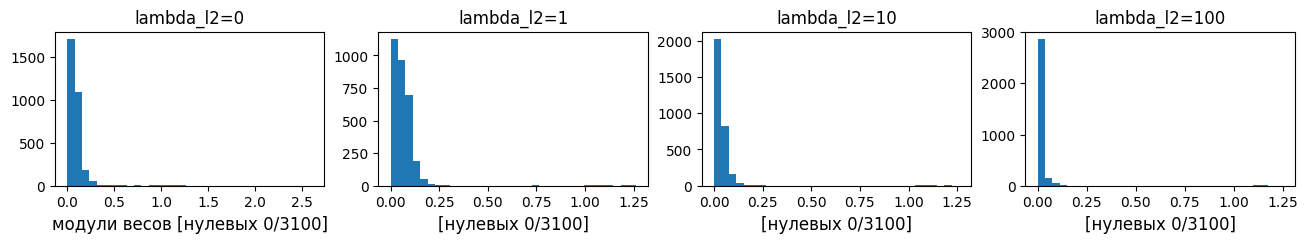

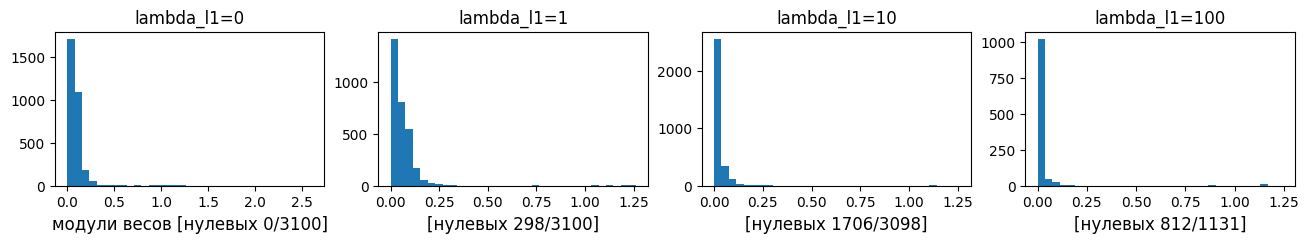

In [52]:
lgb_tr = lgb.Dataset(X_tr, y_tr)
lgb_val = lgb.Dataset(X_val, y_val)

for reg_param in ['lambda_l2', 'lambda_l1']:
    fig, ax = plt.subplots(1, 4, figsize=(16, 2))
    for i, reg_value in enumerate([0, 1, 10, 100]):
        params = {
            'objective': 'binary',
            'nthread': 4,
            'eta': 0.1,
            reg_param: reg_value,
            'verbose': -1
        }
        model = lgb.train(params, train_set=lgb_tr, num_boost_round=100)
        leaf_values = model.trees_to_dataframe().query('split_feature.isnull()').value.abs().values
        n_zeros = (leaf_values == 0).sum()

        ax[i].set_title(f'{reg_param}={reg_value}')
        ax[i].hist(leaf_values, bins=33)
        title = f'[нулевых {n_zeros}/{leaf_values.shape[0]}]'
        if i == 0:
            title = 'модули весов ' + title
        ax[i].set_xlabel(title, fontsize=12)
    plt.show()

Подводим итоги. Условно гиперпараметры можно разделить на несколько категорий:
1. Настраиваем всегда — `eta`, `max_cat_to_onehot`.
2. Подбираем по желанию — `max_leaves`, `zero_as_missing`, `reg_alpha`, `reg_lambda`.
3. Для ускорения:
    - настраиваем `data_sample_strategy`;
    - настраиваем `colsample_by...`.
4. Если нужно повысить «надёжность» модели — `min_data_in_leaf`, `min_data_in_bin`, `min_data_per_group`.
5. Гиперпараметры, относящиеся к другим блокам (подробнее в соответствующих блоках).
6. Гиперпараметры, которые настраиваются в определённых ситуациях / режимах обучения (см. блок со звёздочкой ниже).
7. Всё остальное (данные, которые почти не используются).

> **Важно.** Количество деревьев мы никогда не настраиваем, а подбираем с помощью `early_stopping`.

Ранее мы говорили о том, что тюнинг гиперпараметров градиентного бустинга не даст ощутимый прирост качества, поэтому делать это стоит в последнюю очередь. Для начала протестируй подходы, которые вероятнее приведут к приросту. Например, интерпретация модели, `Feature Engineering`, настройка весов на объектах, выбор метрики для раннего останова или чистка данных.


## *LightGBM (тема для самостоятельного изучения)

Данный раздел посвящён конструированию кастомных лоссов и обзору классных фишек библиотеки. Предназначен для самостоятельного изучения.

Прежде чем говорить о лоссах, разберём, как задать начальные приближения.


### Как задать начальные приближения

Вспомним, что каждое дерево строится по предпосчитанным $g_i = L'(y_i, \hat{y_i}^{(k-1)}), h_i = L''(y_i, \hat{y_i}^{(k-1)})$ в точках, равных предсказаниям предыдущих деревьев. Соответственно, чтобы построить первое дерево нужны начальные приближения на эти точки.

Их можно задать:

* Автоматически через параметр `boost_from_average`. Он устанавливает всем объектам одинаковое начальное приближение, которое зависит от среднего таргета.
* Вручную задать весь вектор начальных приближений через аргумент `init_score` конструктора `lgb.Dataset`.

Ниже — два блока кода с этими вариантами.


In [ ]:
lgb_tr = lgb.Dataset(X_tr, y_tr)

params.update({
    'scale_pos_weight': 1, # Сбросим веса с предыдущего блока
    'is_unbalance': False, # Сбросим веса с предыдущего блока
    'boost_from_average': True, # НЕ работает с кастомными лоссами
    'verbose': 1,

    'lambda_l1': 0, # Уберём значения из прошлого блока
    'lambda_l2': 0 # Уберём значения из прошлого блока
})

# Смотрим последние две [Info] строчки вывода
model = lgb.train(params, train_set=lgb_tr, num_boost_round=10)

In [ ]:
from scipy.special import logit

y_tr.value_counts(normalize=True), logit(0.24286)

Задавая начальные приближения вручную, нужно понимать, что эти данные — «предсказание предыдущих деревьев на первой итерации» или «единица измерения» этих начальных приближений («сырые скоры», а не вероятности). Рассмотрим пример, как задать начальные приближения через предсказания уже обученной модели градиентного бустинга.

Для сравнения обучим две модели на одинаковых параметрах:

* Один ансамбль будет получен в результате непрерывного построения 100 деревьев.
* Второй — построением 10 деревьев на основе предсказаний первичной модели (90 деревьев).
Формулировка станет понятнее, если её разобрать в коде.


In [ ]:
lgb_tr = lgb.Dataset(X_tr, y_tr)
params.update({
    'verbose': -1
})

# 1-й вариант: 100 деревьев разом
model = lgb.train(params, train_set=lgb_tr, num_boost_round=100)
y_raw = model.predict(X_tr, raw_score=True)
print('Было:', y_raw[:5])


# 2-й вариант: 90 + 10
model = lgb.train(params, train_set=lgb_tr, num_boost_round=90)
init_score = model.predict(X_tr, raw_score=True)

lgb_tr = lgb.Dataset(X_tr, y_tr, init_score=init_score)
model = lgb.train(params, train_set=lgb_tr, num_boost_round=10)
y_raw = model.predict(X_tr, raw_score=True)
print('Без добавки init_score:', y_raw[:5])
print('С добавкой:', y_raw[:5] + init_score[:5])

# Нарисуем
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].set_title('Без добавки init_score')
sns.histplot(x=y_raw, hue=y_tr, bins=33, ax=ax[0])
ax[1].set_title('С добавкой')
sns.histplot(x=y_raw + init_score, hue=y_tr, bins=33, ax=ax[1]);

> **Важно.** При обучении одной модели на основе предсказаний другой, нужно добавлять начальные приближения к предсказанию (библиотека не сделает это автоматически). Если использовать валидационный датасет, ему тоже нужно прописать `init_scores`, чтобы всё работало корректно. При проектировании собственных лоссов и метрик приставка `init_scores` уже включена в аргумент `preds` и не требует дополнительных действий.

Такое «дообучение» моделей может быть полезно в связи со следующим блоком.


### Кастомные лоссы

Как и в случае с метриками, иногда необходимо написать кастомный лосс для обучения. Такая потребность может возникнуть в связи с необычной целевой метрикой, например:
* асимметричной — когда штраф за переоценку не равен штрафу за недооценку;
* ϵ-нечувствительной — когда нет штрафа за ошибку по модулю меньше ϵ;
* завязанной на другой признак в данных (например, в предсказаниях фрода при снятии наличных из банкомата целевой метрикой может быть сумма «спасённых» денег).

Чаще всего в таких случаях стандартные лоссы будут слабо сонаправлены с целевой метрикой и процесс обучения будет идти не в том направлении. Для таких случаев есть механизм, позволяющий реализовать собственный лосс и запустить обучение бустинга уже на нём!


Кастомный лосс в `LightGBM` должен иметь следующий шаблон:
```python
def custom_loss(preds: np.array, train_data: lgb.Dataset):
    '''
    preds: «сырые» предсказания на объектах
    train_data: lgb.Dataset с обучающей выборкой

    Нужно вернуть «градиенты» и «гессианы»
        — векторы длины N первых и вторых производных лосса по предсказанным значениям
    '''
    y_true = train_data.get_label()
    object_weights = train_data.get_weight() # Если надо

    grad, hess = calc_grad_hess(y_true, preds)
    return grad, hess
```

От кастомного лосса нам нужны только его первые и вторые производные: $g_i = L'(y_i, \hat{y_i}), h_i = L''(y_i, \hat{y_i})$, где $L$ — отдельное слагаемое для каждого объекта $L_{total} = \sum_{i=1}^{N}{L(y_i, \hat{y_i})}$.

Например, для L2-лосса $L(y_{true}, y_{pred}) = \frac12 (y_{true} - y_{pred})^2$. Тогда $g_i = (\hat{y_i} - y_i), h_i = 1$.

Для примера рассмотрим `LogLoss`.


In [ ]:
from scipy.special import expit
from sklearn.metrics import log_loss
from functools import partial


def custom_log_loss(preds, train_data):
    y_prob = expit(preds)
    y_true = train_data.get_label()
    w = train_data.get_weight() # Можно использовать как хочется, но мы не будем

    grad = y_prob - y_true
    hess = y_prob * (1 - y_prob)

    return grad, hess

def custom_log_loss_metric(preds, train_data, is_custom_objective=False):
    '''
    Помним, что если у нас лосс — встроенный LogLoss, то в качестве preds приходят вероятности,
        а если лосс кастомный, то сырые скоры.
    Если ты будешь использовать кастомный лосс, то встроенная метрика binary_logloss не распознает подмену и посыпется,
        поэтому при проектировании кастомных лоссов всегда лучше сделать ещё и кастомную метрику
        или же перепроверить встроенную несколько раз.
    '''
    y_prob = expit(preds) if is_custom_objective else preds
    y_true = train_data.get_label()
    w = train_data.get_weight() # Можно использовать как хочется, но мы не будем

    loss_score = log_loss(y_true, y_prob)

    greater_is_better = False
    return 'custom_log_loss', loss_score, greater_is_better


params.update({
    'verbose': -1,
    'objective': 'binary', # custom_log_loss, # <----------- сравнить!
    'boost_from_average': False,
    'metric': 'binary_logloss'
})

is_custom_objective = params['objective'] != 'binary'
print('is_custom_objective:', is_custom_objective)
custom_metric = partial(custom_log_loss_metric, is_custom_objective=is_custom_objective)

model = lgb.train(
    params, train_set=lgb_tr, num_boost_round=20,
    feval=custom_metric,
    callbacks=[lgb.log_evaluation(10)], valid_sets=[lgb_val]
)

При проектировании собственных лоссов может возникнуть проблема: написано всё правильно, но алгоритм «расходится» или плохо работает. Это связано с тем, что погрешность приближения функции $L(y_i, \hat{y_i} + w_i)$ рядом Тейлора до второго члена для каждого лосса разная, и бывает так, что для каких-то лосс-функций и каких-то значений $\hat{y_i}, w_i$ эта погрешность пренебрежительно мала, а для других — настолько высока, что алгоритм перестаёт нормально «учиться».

Например, лоссы `MAE` и `MSE` равны своему «второму  приближению» для любых $\hat{y_i}, w_i$ (при их обучении погрешность нулевая). Поэтому мы можем решать задачу регрессии градиентным бустингом, не боясь за большие веса в листьях, которые могут увеличивать погрешность.

А если мы попытаемся реализовать кастомный MSLE-лосс с формулой
$$L_{MSLE} = \frac1N \sum_{i=1}^{N}{(log(y_i + 1) - log(\hat{y_i} + 1)})^2,$$ то здесь появится погрешность. Поэтому лучше будет преобразовать таргет из $y_i$ в $log(y_i + 1)$ и учиться на MSE с преобразованным таргетом без погрешности.

Часто, когда реализован «непростой лосс» и хочется обучиться на нём с нуля, алгоритм может работать некорректно из-за того, что начальные приближения не подходят для данного лосса. В таких случаях рекомендуется:

1. Сначала обучиться на  проверенном лоссе «из коробки».
2. Затем дообучиться на своём подходящем лоссе, используя начальные приближения из блока выше.

Помни, что для лоссов с высокой погрешностью приближения веса должны быть маленькие, потому нужно тщательно настроить параметры (например, `eta`, `reg_lambda`, `reg_alpha`).


### GBDT-PL (линейные регрессии в листьях вместо констант)

В LightGBM реализована отличная идея из этой [статьи](https://arxiv.org/abs/1802.05640): организовать процесс обучения так, чтобы в листьях вместо констант обучались линейные регрессии на признаках, участвующих в цепочке сплитов, ведущих из корня в лист. Так каждый объект, попавший в лист, будет получать разный скор, основанный на значении своих признаков, что существенно повышает экстраполяционные возможности градиентного бустинга. При этом просадка по времени почти отсутствует. Однако нужно внимательно отнестись к подбору параметра регуляризации. Подробнее читай в статье!  


In [ ]:
lgb_tr = lgb.Dataset(X_tr, y_tr)
params.update({
    'linear_tree': False,
    'verbose': -1
})
%time model = lgb.train(params, train_set=lgb_tr, num_boost_round=200)

lgb_tr = lgb.Dataset(X_tr, y_tr)
params.update({
    'linear_tree': True,
    'linear_lambda': 0.1,
})
%time model = lgb.train(params, train_set=lgb_tr, num_boost_round=200)

### CEGB (Cost-Efficient Gradient Boosting)

Иногда нужно, чтобы модель использовала как можно меньше признаков из тех, что поданы на вход. Например, в случаях, когда модель должна быстро работать в онлайне, а признаки для модели тянутся из базы. В таком случае нельзя тратить много времени на то, чтобы подтягивать большое количество табличек. Поэтому здесь хотелось бы сократить по возможности их количество. На этапе обучения ты можешь задать штрафы на признаки, после чего модель будет учитывать, что каждый новый признак, появляющийся в сплитах, добавляет какой-то штраф в лосс.

В `LightGBM` есть возможность встроить такие ограничения, а также штрафы на глубину строящихся деревьев в процессе обучения. Подробнее изучить тему можно:
* в статье [«Экономически эффективный градиентный бустинг»](https://proceedings.neurips.cc/paper_files/paper/2017/file/4fac9ba115140ac4f1c22da82aa0bc7f-Paper.pdf);
* блоке [«Cost Efficient Gradient Boosting»](https://lightgbm.readthedocs.io/en/latest/Advanced-Topics.html#cost-efficient-gradient-boosting) документации `LightGBM`.


#### Дополнительные настройки

- `monotone_constraints` — можно провоцировать зависимости вида «если $f_{1i} > f_{1j}$, то $\hat{y_i} > \hat{y_j}$».
- `interaction_constraints` — можно ограничить количество признаков, которые могут встречаться в одной ветке.
- `forced_splits` — можно провоцировать сплиты конкретного вида в начале каждого дерева.
- `boosting` = 'rf' — можно обучить случайный лес.


## Теперь ты умеешь

* Обучать модель `LightGBM` «из коробки».
* Настраивать `early_stopping` и логировать метрики.
* Создавать кастомные метрики.
* Задавать веса на объектах при необходимости.
* Интерпретировать построенную модель на базовом уровне.
* Тюнить гиперпараметры, понимая их смысл.

